In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# 1. LOAD DATA & MODEL PREDICTIONS
# X_test (features) and y_test (true labels)
X_test = pd.read_csv('../data/X_test.csv')
y_test = pd.read_csv('../data/y_test.csv').values.ravel()

In [15]:
# Load model (LightGBM) to generate predictions again
# (In a production script, we'd load the .pkl file, but re-training is fast/safe here)
from lightgbm import LGBMClassifier
X_train = pd.read_csv('../data/X_train_resampled.csv')
y_train = pd.read_csv('../data/y_train_resampled.csv').values.ravel()

In [16]:
model = LGBMClassifier(random_state=42, verbose=-1)
model.fit(X_train, y_train)

LGBMClassifier(random_state=42, verbose=-1)

In [17]:
# Get predictions
y_pred = model.predict(X_test)

In [18]:
# Combine into a single DataFrame for analysis
analysis_df = X_test.copy()
analysis_df['True_Label'] = y_test
analysis_df['Predicted_Label'] = y_pred

print("Data ready for Fairness Analysis.")

Data ready for Fairness Analysis.


In [19]:
# ---------------------------------------------------------
# 2. DEFINE PROTECTED GROUPS (The "Fairness" Check)
# ---------------------------------------------------------
# Since we don't have Race/Gender, we use Economic Proxies.
# Proxy 1: Income Level (Low vs High)
median_income = analysis_df['annual_income'].median()
analysis_df['Group_Income'] = np.where(analysis_df['annual_income'] < median_income, 'Low Income', 'High Income')

In [ ]:
# Proxy 2: Home Ownership (Rent vs Owner)
# We assume 'MORTGAGE' and 'OWN' are "Privileged", 'RENT' is "Unprivileged"
# Note: One-hot encoded columns might be 'homeownership_RENT', 'homeownership_OWN', etc.
# Reconstruct it from the dummy columns if needed, or use the most prominent one.
if 'homeownership_RENT' in analysis_df.columns:
    analysis_df['Group_Home'] = np.where(analysis_df['homeownership_RENT'] == 1, 'Renter', 'Owner')
else:
    # If using cleaned dataset columns, adjust logic. 
    # For now, I stick to Income which is there.
    analysis_df['Group_Home'] = 'Unknown'

print(f"\nSplit check: {analysis_df['Group_Income'].value_counts()}")


Split check: Group_Income
High Income    1557
Low Income     1436
Name: count, dtype: int64


In [21]:
# ---------------------------------------------------------
# 3. CALCULATE METRICS BY GROUP
# ---------------------------------------------------------
# We look at "False Positive Rate" (FPR). 
# High FPR for Low Income = Model unfairly flags them as risky even when they are good.

def calculate_group_metrics(df, group_col):
    groups = df[group_col].unique()
    results = []
    
    for group in groups:
        subset = df[df[group_col] == group]
        if len(subset) == 0: continue
        
        # Confusion Matrix
        cm = confusion_matrix(subset['True_Label'], subset['Predicted_Label'])
        tn, fp, fn, tp = cm.ravel()
        
        # Metrics
        accuracy = (tp + tn) / len(subset)
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0 # "False Alarm Rate"
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        
        results.append({
            'Group': group,
            'Accuracy': accuracy,
            'False_Positive_Rate': fpr, 
            'Recall': recall,
            'Count': len(subset)
        })
    
    return pd.DataFrame(results)

# Run Analysis
income_metrics = calculate_group_metrics(analysis_df, 'Group_Income')

print("\n=== FAIRNESS REPORT: INCOME LEVEL ===")
print(income_metrics)


=== FAIRNESS REPORT: INCOME LEVEL ===
         Group  Accuracy  False_Positive_Rate    Recall  Count
0   Low Income  0.983287             0.000708  0.041667   1436
1  High Income  0.980090             0.001309  0.000000   1557


C:\Users\Yahya\AppData\Local\Temp\ipykernel_1292\68242667.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Group', y='False_Positive_Rate', data=income_metrics, palette='magma')


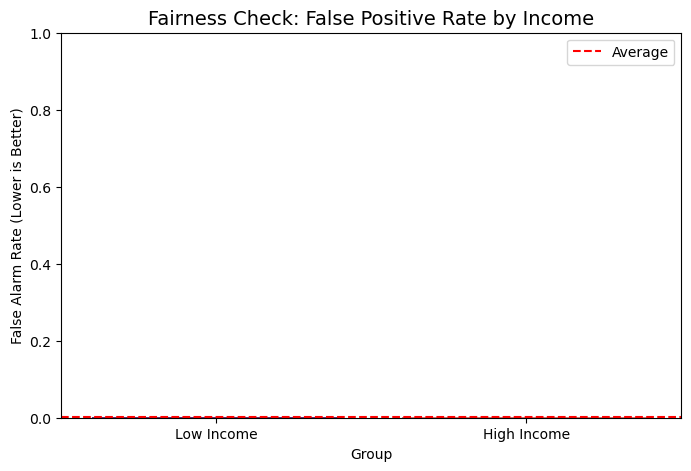

In [ ]:
# ---------------------------------------------------------
# 4. VISUALIZE DISPARITY
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.barplot(x='Group', y='False_Positive_Rate', data=income_metrics, palette='magma')
plt.title('Fairness Check: False Positive Rate by Income', fontsize=14)
plt.ylabel('False Alarm Rate (Lower is Better)')
plt.ylim(0, 1)

# Add line for "Disparate Impact" threshold (arbitrary visual guide)
plt.axhline(y=income_metrics['False_Positive_Rate'].mean(), color='red', linestyle='--', label='Average')
plt.legend()
plt.savefig('../plots/fairness_income.png')
plt.show()

C:\Users\Yahya\AppData\Local\Temp\ipykernel_1292\3108356166.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Group', y='False_Positive_Rate', data=income_metrics, palette='magma')


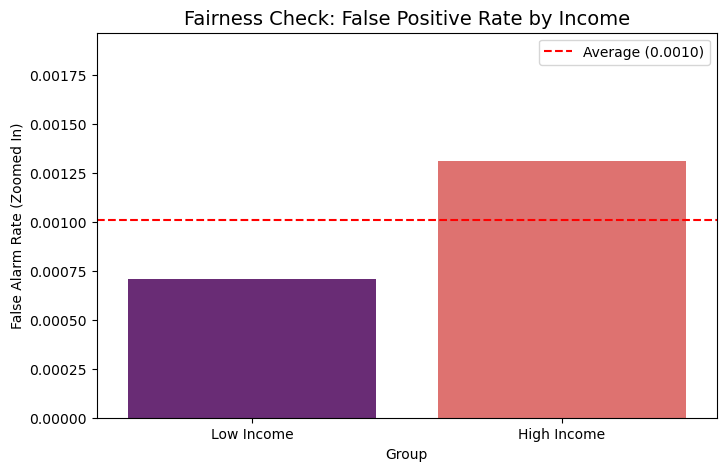

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Group', y='False_Positive_Rate', data=income_metrics, palette='magma')
plt.title('Fairness Check: False Positive Rate by Income', fontsize=14)
plt.ylabel('False Alarm Rate (Zoomed In)')

# Set the limit to slightly above the max error found, not 1.0
max_error = income_metrics['False_Positive_Rate'].max()
plt.ylim(0, max_error * 1.5) # Zoom in to show the bars clearly

# Add line for Average
avg_fpr = income_metrics['False_Positive_Rate'].mean()
plt.axhline(y=avg_fpr, color='red', linestyle='--', label=f'Average ({avg_fpr:.4f})')

plt.legend()
plt.savefig('../plots/fairness_income_zoomed.png')
plt.show()

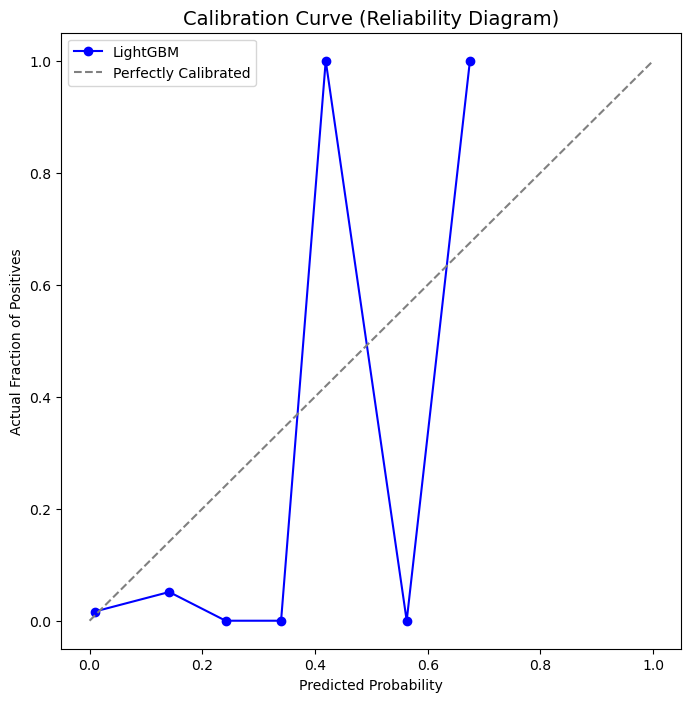


SUCCESS: Fairness and Compliance Analysis Complete!


In [ ]:
# 5. CALIBRATION PLOT (Basel III Requirement)
# Does "80% Risk" actually mean 80% of people default?
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, model.predict_proba(X_test)[:, 1], n_bins=10)

plt.figure(figsize=(8, 8))
plt.plot(prob_pred, prob_true, marker='o', label='LightGBM', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
plt.xlabel('Predicted Probability')
plt.ylabel('Actual Fraction of Positives')
plt.title('Calibration Curve (Reliability Diagram)', fontsize=14)
plt.legend()
plt.savefig('../plots/calibration_plot.png')
plt.show()

print("\nSUCCESS: Fairness and Compliance Analysis Complete!")